# 32 · Test whether the phase and tensor gains transfer

The primary contrast compares aligned local Q with aligned Q magnitude on source-excluded same-category top-1. Both methods use the same allowed search. The conventional aligned structure tensor is the strongest classical comparator from the MNIST experiment. Report the two datasets side by side, using 12 disjoint 40-image galleries in each.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage8 import BASELINES,FROZEN,VIEWS,contrast
from observables.stage9 import load_fashion,observations,cross_dataset_contrast
from observables.stage6 import CONDITIONS
OUT=ROOT/'results'/'stage9'
MNIST=ROOT/'results'/'stage8'
CATEGORIES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Build the matched comparison
The Stage 8 implementations of local Q, conventional tensor, ZNCC, standard HOG and frozen encoders are reused directly. The fixed frozen rows again use the same 56 × 56 inputs and checkpoints. Compare local mean and local Q on identical intermediate grids. These settings are carried over from MNIST. No Fashion-MNIST score is used to pick methods or adjust weights.

In [3]:
fashion=pd.read_csv(OUT/'decisions.csv.gz').query("gallery_type=='full'")
mnist=pd.read_csv(MNIST/'decisions.csv.gz').query("panel=='replication' and gallery_type=='full'")
assert len(fashion)==len(mnist)==3840*27
fs=json.loads((OUT/'frozen_manifest.json').read_text())
ms=json.loads((MNIST/'frozen_manifest.json').read_text())
assert fs['input_size']==ms['input_size']==56
for name in fs['models']:
    assert fs['models'][name]['sha256']==ms['models'][name]['sha256']
keep=['aligned pixels','aligned ZNCC','standard HOG','HOG after ZNCC','aligned structure tensor',
      'aligned Q magnitude','local Q','aligned local Q','ResNet-50 cosine','ResNet-50 local Q',
      'EfficientNet-B0 cosine','EfficientNet-B0 local Q','uniform profile','uniform minus triplets']
values=pd.concat([f.groupby('method')[['identity','class']].mean().loc[keep]
                 for f in [mnist,fashion]],axis=1,keys=['MNIST','Fashion-MNIST'])*100
display(values.round(2))
values.to_csv(OUT/'cross_dataset_comparison.csv')

MNIST        Fashion-MNIST       
                         identity  class      identity  class
method                                                       
aligned pixels              93.91  52.27         88.93  44.53
aligned ZNCC                92.81  55.70         89.95  50.68
standard HOG                79.17  50.00         64.19  37.89
HOG after ZNCC              87.03  50.23         68.23  40.23
aligned structure tensor    95.16  62.50         91.43  53.36
aligned Q magnitude         92.47  53.93         71.93  40.94
local Q                     84.43  63.18         78.23  49.64
aligned local Q             95.26  64.79         90.86  53.41
ResNet-50 cosine            61.46  38.88         59.32  35.78
ResNet-50 local Q           81.41  51.48         75.26  43.98
EfficientNet-B0 cosine      70.44  40.81         67.21  39.17
EfficientNet-B0 local Q     70.34  36.28         69.66  37.01
uniform profile             86.02  45.70         75.16  40.29
uniform minus triplets      88.20  49.84         77.79  40.21

## Keep the effect and the dataset difference distinct
Within each dataset, compute paired differences across galleries and percentile intervals. To estimate the difference between the paired effects on the two datasets, independently resample each set of galleries and subtract the draw means. The primary orientation-phase contrast was specified before examining Fashion-MNIST. Other intervals are pointwise and descriptive.

In [5]:
comparisons=[
 ('aligned local Q','aligned Q magnitude'),('aligned local Q','aligned structure tensor'),
 ('aligned local Q','aligned pixels'),('aligned local Q','aligned ZNCC'),
 ('uniform minus triplets','uniform profile'),
 ('ResNet-50 local Q','ResNet-50 local mean'),('EfficientNet-B0 local Q','EfficientNet-B0 local mean')]
rows=[]
for a,b in comparisons:
    for ep in ['identity','class']:
        for label,estimate in [('MNIST',contrast(mnist,a,b,ep)),
                               ('Fashion-MNIST',contrast(fashion,a,b,ep)),
                               ('Fashion minus MNIST',cross_dataset_contrast(fashion,mnist,a,b,ep))]:
            rows.append((label,a,b,ep,*estimate))
effects=pd.DataFrame(rows,columns=['panel','left','right','endpoint','difference','low95','high95'])
effects.to_csv(OUT/'transfer_contrasts.csv',index=False)
display(effects.query("endpoint=='class'").round(4))

,panel,left,right,endpoint,difference,low95,high95
3,MNIST,aligned local Q,aligned Q magnitude,class,0.1086,0.0812,0.1378
4,Fashion-MNIST,aligned local Q,aligned Q magnitude,class,0.1247,0.1052,0.1453
5,Fashion minus MNIST,aligned local Q,aligned Q magnitude,class,0.0161,-0.0174,0.0490
9,MNIST,aligned local Q,aligned structure tensor,class,0.0229,0.0094,0.0354
10,Fashion-MNIST,aligned local Q,aligned structure tensor,class,0.0005,-0.0086,0.0102
11,Fashion minus MNIST,aligned local Q,aligned structure tensor,class,-0.0224,-0.0385,-0.0060
15,MNIST,aligned local Q,aligned pixels,class,0.1253,0.0958,0.1544
16,Fashion-MNIST,aligned local Q,aligned pixels,class,0.0888,0.0576,0.1221
17,Fashion minus MNIST,aligned local Q,aligned pixels,class,-0.0365,-0.0779,0.0078
21,MNIST,aligned local Q,aligned ZNCC,class,0.0909,0.0659,0.1159


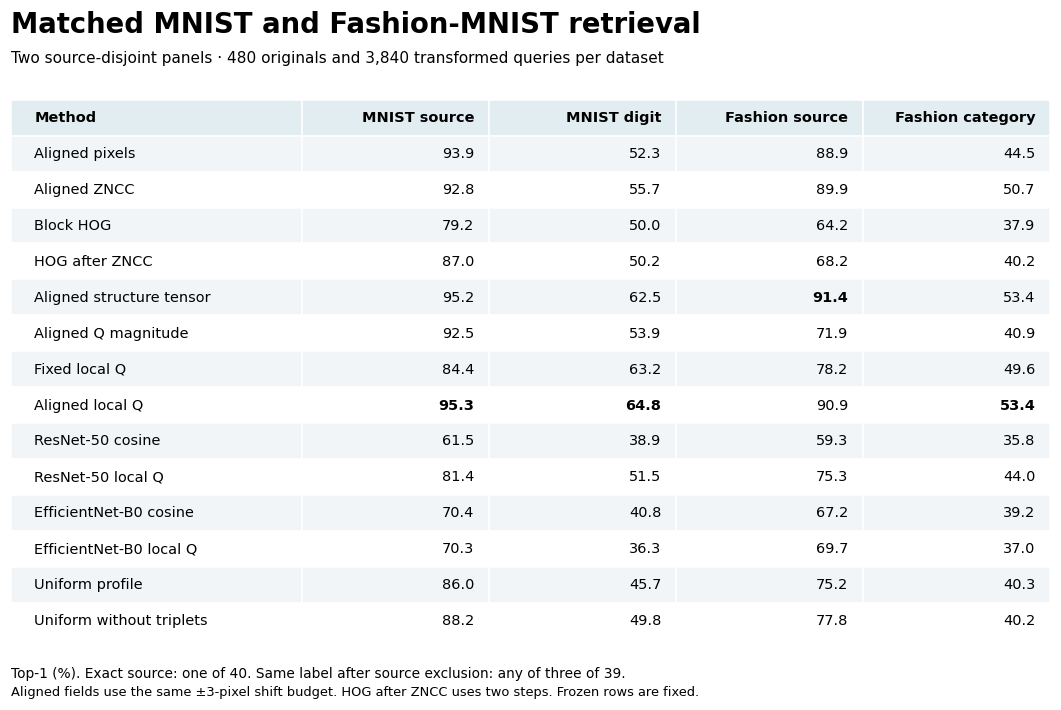

In [4]:
labels=['MNIST source','MNIST digit','Fashion source','Fashion category']
names=['Aligned pixels','Aligned ZNCC','Block HOG','HOG after ZNCC','Aligned structure tensor',
       'Aligned Q magnitude','Fixed local Q','Aligned local Q','ResNet-50 cosine','ResNet-50 local Q',
       'EfficientNet-B0 cosine','EfficientNet-B0 local Q','Uniform profile','Uniform without triplets']
rows=[[name,*[f'{x:.1f}' for x in row]] for name,row in zip(names,values.to_numpy())]
fig,ax=plt.subplots(figsize=(10.5,6.8))
ax.set_axis_off();ax.set_position([.05,.13,.9,.72])
fig.text(.05,.94,'Matched MNIST and Fashion-MNIST retrieval',fontsize=18,weight='bold')
fig.text(.05,.90,'Two source-disjoint panels · 480 originals and 3,840 transformed queries per dataset',fontsize=10)
table=ax.table(cellText=rows,colLabels=['Method',*labels],cellLoc='right',colLoc='right',
               colWidths=[.28,.18,.18,.18,.18],bbox=[0,0,1,1])
table.auto_set_font_size(False);table.set_fontsize(9.5)
array=values.to_numpy()
for (r,c),cell in table.get_celld().items():
    cell.set_edgecolor('white');cell.PAD=.08
    cell.set_facecolor('#e2edf2' if r==0 else '#f1f5f7' if r%2 else 'white')
    if c==0:cell.get_text().set_ha('left')
    if r==0 or (c>0 and array[r-1,c-1]==array[:,c-1].max()):cell.get_text().set_weight('bold')
fig.text(.05,.078,'Top-1 (%). Exact source: one of 40. Same label after source exclusion: any of three of 39.',fontsize=9)
fig.text(.05,.053,'Aligned fields use the same ±3-pixel shift budget. HOG after ZNCC uses two steps. Frozen rows are fixed.',fontsize=8.5)
show('32_fashion_transfer_table')

## Interpretation
A phase gain can transfer even if the preferred alignment policy or the ordering against a stronger baseline changes. The table compares two domains under a common protocol. It does not measure ordinary classification accuracy or performance on other image corpora.

## Locate the larger exact-source phase gain
The aggregate exact-source phase advantage is much larger on Fashion-MNIST. Break it down by perturbation to see whether the gain is broad or concentrated. This is a descriptive decomposition of the frozen methods.

In [7]:
both=pd.concat([mnist.assign(dataset='MNIST'),fashion.assign(dataset='Fashion-MNIST')],ignore_index=True)
by=both.groupby(['dataset','condition','method'])[['identity','class']].mean()
by.to_csv(OUT/'condition_summary.csv')
p=by['identity'].unstack('method')
phase=p['aligned local Q']-p['aligned Q magnitude']
display((100*phase.unstack('dataset').loc[list(VIEWS)]).round(2).rename_axis('Exact-source phase gain (pp)'))

dataset,Fashion-MNIST,MNIST
Exact-source phase gain (pp),,
shift,0.00,0.00
gain,0.00,0.00
noise,69.79,10.00
blur,12.50,1.88
rotation,0.42,5.21
crop,0.00,0.00
occlusion,0.00,-0.42
shift + noise,68.75,5.63
